In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

### Step 1: Checking Uploaded Files

**Objective:** Identify the CSV files uploaded to Kaggle.

We use Python's `os` module to check the contents of our dataset and data dictionary folders.

- `import os` – Loads tools for working with files and folders.
- `dataset_folder` – Stores the main dataset folder location.
- `dictionary_folder` – Stores the data dictionary folder location.
- `os.listdir()` – Shows the files inside each folder.
- `print()` – Displays the results.

**Purpose:** Find the exact CSV filenames before loading them with Pandas.

In [1]:

import os

dataset_folder = "/kaggle/input/datasets/riyaydv08/dataset-hcl"
dictionary_folder = "/kaggle/input/datasets/riyaydv08/data-dictionary-hcl"

print("MAIN DATASET FILES:")
print(os.listdir(dataset_folder))

print("\nDATA DICTIONARY FILES:")
print(os.listdir(dictionary_folder))


MAIN DATASET FILES:
['dataset.csv']

DATA DICTIONARY FILES:
['data_dictionary.csv']


### Step 2: Loading the Dataset Using Pandas

**Objective:** Load the dataset and data dictionary into Python.

- `import pandas as pd` – Imports the Pandas library.
- `pd.read_csv()` – Reads a CSV file.
- `df` – Stores the main dataset as a DataFrame.
- `data_dict` – Stores the data dictionary.
- `df.head()` – Displays the first 5 rows.

**Purpose:** Prepare our data for exploration and analysis.

In [2]:
import pandas as pd

# Load the main dataset
df = pd.read_csv(
    "/kaggle/input/datasets/riyaydv08/dataset-hcl/dataset.csv"
)

# Load the data dictionary
data_dict = pd.read_csv(
    "/kaggle/input/datasets/riyaydv08/data-dictionary-hcl/data_dictionary.csv"
)

# Display the first 5 rows
print("MAIN DATASET:")
display(df.head())

print("DATA DICTIONARY:")
display(data_dict.head())

MAIN DATASET:


,resume_id,job_role,years_exp,skills_matched,education_score,keyword_density,predicted_score,shortlisted
0,R0001,Data_Analyst,3,8,73,0.129,46.1,0
1,R0002,Data_Analyst,5,6,67,0.747,97.7,1
2,R0003,Software_Engineer,9,11,89,0.713,61.1,1
3,R0004,HR_Executive,4,8,99,0.459,79.9,0
4,R0005,Software_Engineer,10,4,91,0.608,57.8,1


DATA DICTIONARY:


,column_name,data_type,sample_value_1,sample_value_2,sample_value_3,nullable,description_fill_in
0,resume_id,object/numeric,R0001,R0002,R0003,No,resume_id — [Learner to fill in description]
1,job_role,object/numeric,Data_Analyst,Data_Analyst,Software_Engineer,No,job_role — [Learner to fill in description]
2,years_exp,object/numeric,3,5,9,No,years_exp — [Learner to fill in description]
3,skills_matched,object/numeric,8,6,11,No,skills_matched — [Learner to fill in description]
4,education_score,object/numeric,73,67,89,No,education_score — [Learner to fill in descript...


### Step 3: Understanding Dataset Structure

**Objective:** Examine the size, columns, and data types of our dataset.

- `df.shape` – Shows the number of rows and columns.
- `df.columns` – Lists all column names.
- `df.info()` – Shows data types and non-null values.
- `df.isnull().sum()` – Counts missing values in each column.

**Purpose:** Understand our dataset before cleaning and analysis.

In [3]:
# Check dataset dimensions
print("DATASET SHAPE:")
print(df.shape)

# Display column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Display dataset information
print("\nDATASET INFORMATION:")
df.info()

# Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

DATASET SHAPE:
(500, 8)

COLUMN NAMES:
['resume_id', 'job_role', 'years_exp', 'skills_matched', 'education_score', 'keyword_density', 'predicted_score', 'shortlisted']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resume_id        500 non-null    object 
 1   job_role         500 non-null    object 
 2   years_exp        500 non-null    int64  
 3   skills_matched   500 non-null    int64  
 4   education_score  500 non-null    int64  
 5   keyword_density  500 non-null    float64
 6   predicted_score  500 non-null    float64
 7   shortlisted      500 non-null    int64  
dtypes: float64(2), int64(4), object(2)
memory usage: 31.4+ KB

MISSING VALUES:
resume_id          0
job_role           0
years_exp          0
skills_matched     0
education_score    0
keyword_density    0
predicted_score    0
shortlisted        

### Step 4: Checking Duplicate Records

**Objective:** Identify repeated records in the dataset.

- `df.duplicated()` – Checks for identical rows.
- `.sum()` – Counts how many duplicate rows exist.
- `df["resume_id"].duplicated()` – Checks for repeated resume IDs.

**Purpose:** Detect duplicate data before analysis and model training.

In [4]:
# Count completely identical rows
duplicate_rows = df.duplicated().sum()

# Count repeated resume IDs
duplicate_ids = df["resume_id"].duplicated().sum()

print("Duplicate rows:", duplicate_rows)
print("Duplicate resume IDs:", duplicate_ids)

Duplicate rows: 0
Duplicate resume IDs: 0


### Step 5: Statistical Summary

**Objective:** Understand the numerical features of our dataset.

- `df.describe()` – Calculates descriptive statistics.
- `count` – Number of available values.
- `mean` – Average value.
- `std` – Standard deviation (data spread).
- `min` / `max` – Smallest and largest values.
- `25%`, `50%`, `75%` – Quartiles of the data.

**Purpose:** Identify typical values, ranges, and unusual patterns.

In [5]:
# Generate statistical summary
summary = df.describe()

# Display the summary as a table
display(summary)

,years_exp,skills_matched,education_score,keyword_density,predicted_score,shortlisted
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000
mean,7.458000,8.848000,80.314000,0.491682,68.033400,0.34600
std,4.698978,3.729439,11.979416,0.226735,17.569519,0.47617
min,0.000000,3.000000,60.000000,0.101000,40.100000,0.00000
25%,3.000000,6.000000,69.000000,0.295750,51.300000,0.00000
50%,7.000000,9.000000,80.000000,0.492500,67.700000,0.00000
75%,12.000000,12.000000,91.000000,0.697250,83.300000,1.00000
max,15.000000,15.000000,100.000000,0.900000,100.000000,1.00000


### 6. Checking Shortlisted and Rejected Candidates

**Objective:** Count how many candidates were shortlisted or rejected.

- `df["shortlisted"]` – Selects the target column.
- `value_counts()` – Counts candidates in each category.
- `sort_index()` – Arranges the results by category.

**Purpose:** Understand the distribution of shortlisted (1) and rejected (0) candidates before training our ML model.

In [6]:
# Count shortlisted and rejected candidates
shortlist_counts = df["shortlisted"].value_counts().sort_index()

print("CANDIDATE SHORTLISTING DISTRIBUTION:")
print(shortlist_counts)

# Calculate percentages
shortlist_percentages = df["shortlisted"].value_counts(
    normalize=True
).sort_index() * 100

print("\nPERCENTAGE DISTRIBUTION:")
print(shortlist_percentages.round(2))

CANDIDATE SHORTLISTING DISTRIBUTION:
shortlisted
0    327
1    173
Name: count, dtype: int64

PERCENTAGE DISTRIBUTION:
shortlisted
0    65.4
1    34.6
Name: proportion, dtype: float64


### 7. Understanding Job Role Distribution

**Objective:** Identify the different job roles in our dataset.

- `df["job_role"]` – Selects the job role column.
- `unique()` – Displays distinct job roles.
- `nunique()` – Counts the number of unique roles.
- `value_counts()` – Counts candidates for each role.

**Purpose:** Understand which job roles are represented in our dataset.

In [7]:
# Display unique job roles
print("UNIQUE JOB ROLES:")
print(df["job_role"].unique())

# Count unique job roles
print("\nNUMBER OF JOB ROLES:")
print(df["job_role"].nunique())

# Count candidates in each job role
print("\nCANDIDATES PER JOB ROLE:")
print(df["job_role"].value_counts())

UNIQUE JOB ROLES:
['Data_Analyst' 'Software_Engineer' 'HR_Executive' 'Project_Manager'
 'QA_Engineer']

NUMBER OF JOB ROLES:
5

CANDIDATES PER JOB ROLE:
job_role
HR_Executive         120
QA_Engineer          104
Data_Analyst         102
Software_Engineer     87
Project_Manager       87
Name: count, dtype: int64


### 8. Analyzing Shortlisting by Job Role

**Objective:** Compare shortlisting results across different job roles.

- `pd.crosstab()` – Creates a table comparing two columns.
- `job_role` – Groups candidates by their job role.
- `shortlisted` – Shows whether candidates were shortlisted (1) or not (0).

**Purpose:** Understand how shortlisting outcomes differ between job roles.

In [8]:
# Compare job roles with shortlisting outcomes
role_shortlisting = pd.crosstab(
    df["job_role"],
    df["shortlisted"]
)

# Rename columns for easier understanding
role_shortlisting.columns = ["Not Shortlisted", "Shortlisted"]

# Display the comparison table
print("SHORTLISTING BY JOB ROLE:")
display(role_shortlisting)

SHORTLISTING BY JOB ROLE:


,Not Shortlisted,Shortlisted
job_role,,
Data_Analyst,68,34
HR_Executive,85,35
Project_Manager,51,36
QA_Engineer,67,37
Software_Engineer,56,31


### 9. Calculating Shortlisting Rates by Job Role

**Objective:** Calculate the percentage of shortlisted candidates for each job role.

- `groupby()` – Groups candidates by job role.
- `mean()` – Calculates the average shortlist value.
- `* 100` – Converts the result into a percentage.
- `round(2)` – Rounds values to two decimal places.
- `sort_values()` – Sorts the results.

**Purpose:** Compare shortlisting rates fairly across job roles of different sizes.

In [9]:
# Group candidates by job role and calculate shortlist percentages
shortlist_rates = (
    df.groupby("job_role")["shortlisted"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("SHORTLISTING RATE BY JOB ROLE (%):")
display(shortlist_rates)

SHORTLISTING RATE BY JOB ROLE (%):


job_role
Project_Manager      41.38
Software_Engineer    35.63
QA_Engineer          35.58
Data_Analyst         33.33
HR_Executive         29.17
Name: shortlisted, dtype: float64

### 10. Visualizing Shortlisting Rates by Job Role

**Objective:** Compare shortlisting percentages using a bar chart.

- `matplotlib.pyplot` – Library for creating graphs.
- `plt.bar()` – Creates a bar chart.
- `plt.xlabel()` / `plt.ylabel()` – Adds axis labels.
- `plt.title()` – Adds a chart title.
- `plt.show()` – Displays the chart.

**Purpose:** Visualize differences in shortlisting rates across job roles.

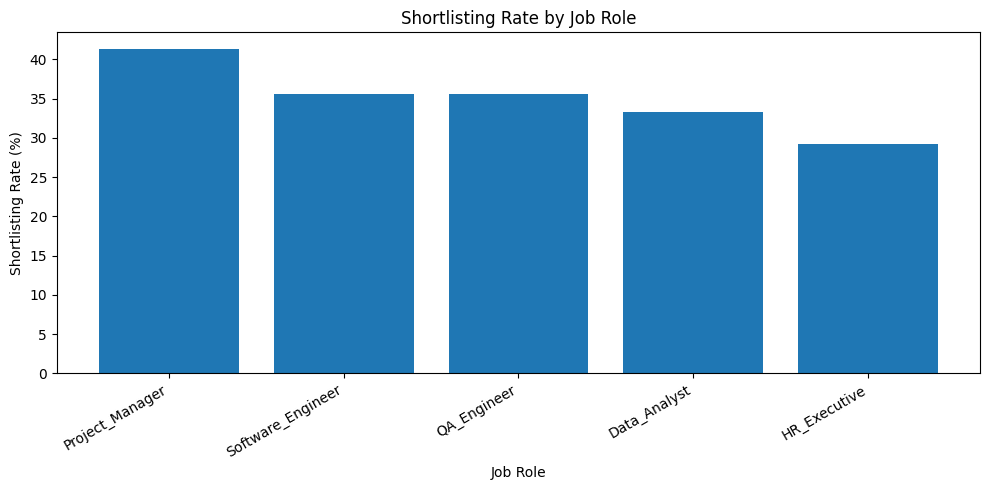

In [10]:
import matplotlib.pyplot as plt

# Set the chart size
plt.figure(figsize=(10, 5))

# Create a bar chart
plt.bar(shortlist_rates.index, shortlist_rates.values)

# Add chart labels
plt.xlabel("Job Role")
plt.ylabel("Shortlisting Rate (%)")
plt.title("Shortlisting Rate by Job Role")

# Rotate job role names for readability
plt.xticks(rotation=30, ha="right")

# Display the chart
plt.tight_layout()
plt.show()

### 11. Analyzing Candidates' Years of Experience

**Objective:** Understand how work experience is distributed among candidates.

- `plt.hist()` – Creates a histogram.
- `bins` – Divides experience values into intervals.
- `plt.xlabel()` – Labels the horizontal axis.
- `plt.ylabel()` – Labels the vertical axis.

**Purpose:** Identify common experience levels and understand the distribution of candidates.

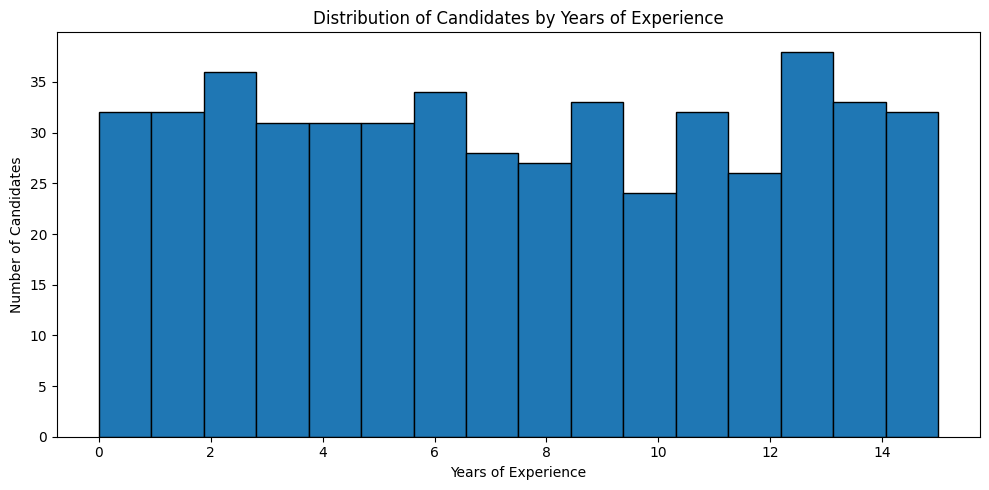

In [11]:
import matplotlib.pyplot as plt

# Set the chart size
plt.figure(figsize=(10, 5))

# Create a histogram of candidate experience
plt.hist(df["years_exp"], bins=16, edgecolor="black")

# Add labels and title
plt.xlabel("Years of Experience")
plt.ylabel("Number of Candidates")
plt.title("Distribution of Candidates by Years of Experience")

# Display the chart
plt.tight_layout()
plt.show()

### 12. Analyzing Skills Matched vs. Shortlisting

**Objective:** Examine the relationship between matched skills and shortlisting.

- `groupby()` – Groups candidates by the number of matched skills.
- `mean()` – Calculates the proportion shortlisted.
- `plt.plot()` – Creates a line graph.
- `marker="o"` – Displays a circle at each data point.

**Purpose:** Understand whether skill matching is associated with candidate shortlisting.

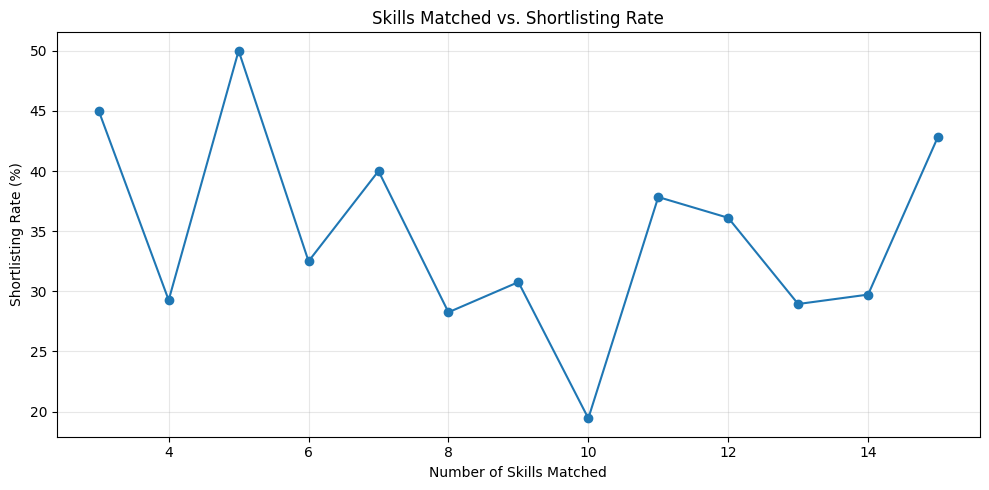

In [12]:
import matplotlib.pyplot as plt

# Calculate shortlisting rate for each skill-match count
skills_shortlist = (
    df.groupby("skills_matched")["shortlisted"]
    .mean()
    .mul(100)
    .sort_index()
)

# Set the chart size
plt.figure(figsize=(10, 5))

# Create a line graph
plt.plot(
    skills_shortlist.index,
    skills_shortlist.values,
    marker="o"
)

# Add labels and title
plt.xlabel("Number of Skills Matched")
plt.ylabel("Shortlisting Rate (%)")
plt.title("Skills Matched vs. Shortlisting Rate")

# Display the graph
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 13. Analyzing Feature Correlations

**Objective:** Identify relationships between numerical features.

- `select_dtypes()` – Selects numerical columns.
- `corr()` – Calculates correlation coefficients.
- `sns.heatmap()` – Visualizes correlations using colors.
- `annot=True` – Displays correlation values.

**Purpose:** Understand feature relationships and identify possible data leakage before ML training.

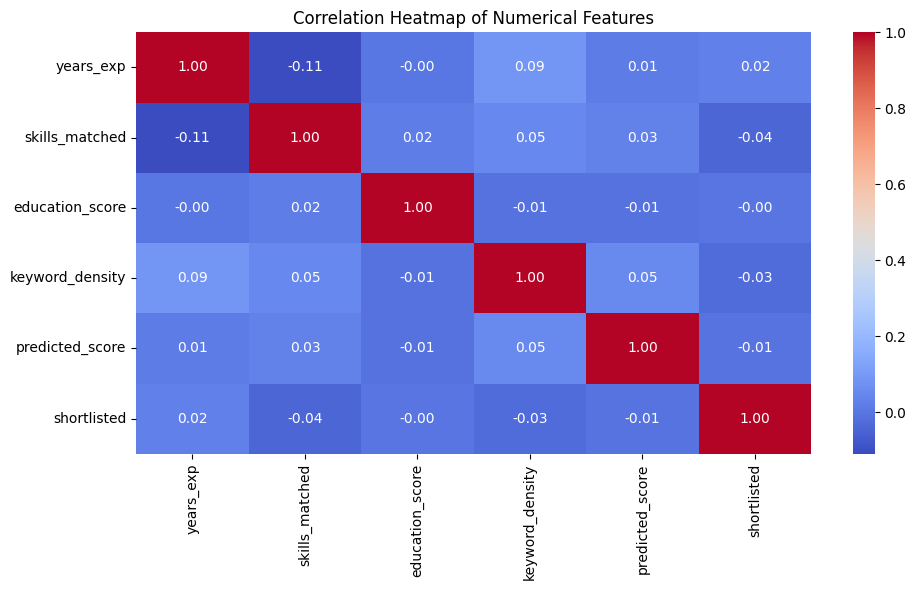

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Create a heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Add title
plt.title("Correlation Heatmap of Numerical Features")

# Display the graph
plt.tight_layout()
plt.show()

### 14. Checking Data Ranges and Outliers

**Objective:** Identify unusual values in numerical features.

- `plt.boxplot()` – Displays data distribution and possible outliers.
- `df[columns]` – Selects numerical features.
- `plt.ylabel()` – Labels the vertical axis.

**Purpose:** Detect unusual values that may affect data quality and ML performance.

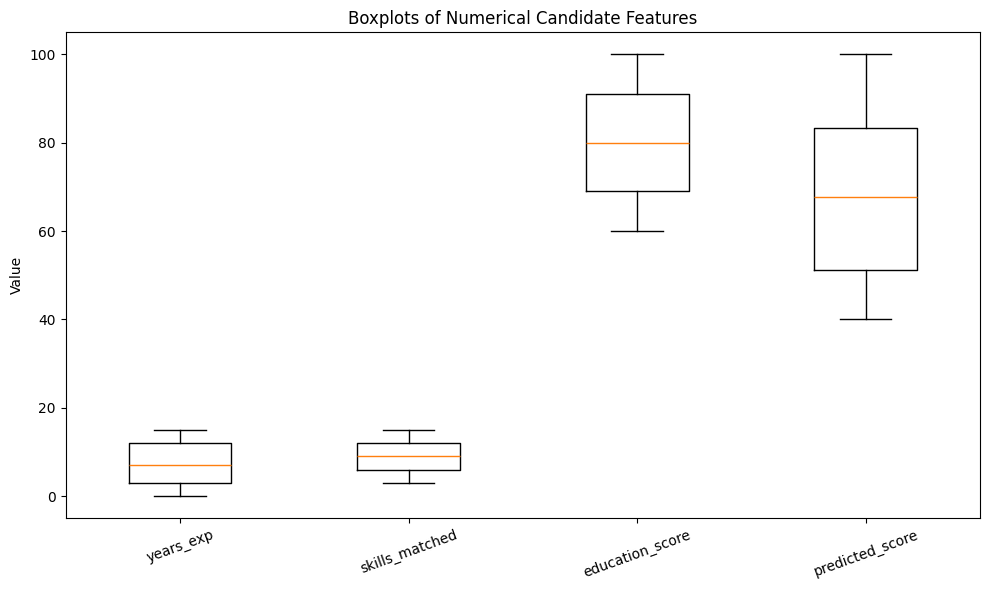

In [14]:
import matplotlib.pyplot as plt

# Select numerical features for analysis
columns = [
    "years_exp",
    "skills_matched",
    "education_score",
    "predicted_score"
]

# Create boxplots
plt.figure(figsize=(10, 6))

plt.boxplot(
    [df[column] for column in columns],
    tick_labels=columns
)

# Add labels and title
plt.ylabel("Value")
plt.title("Boxplots of Numerical Candidate Features")

# Display the chart
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 15. Checking Data Consistency

**Objective:** Identify invalid or unexpected values in the dataset.

- `isin()` – Checks whether values belong to an allowed list.
- `between()` – Checks whether numbers fall within a range.
- `~` – Reverses a condition (NOT).
- `sum()` – Counts records that meet a condition.

**Purpose:** Validate candidate data before preprocessing and ML training.

In [15]:
# Check invalid shortlisting labels
invalid_labels = (~df["shortlisted"].isin([0, 1])).sum()

# Check negative experience values
negative_experience = (df["years_exp"] < 0).sum()

# Check negative skill-match counts
negative_skills = (df["skills_matched"] < 0).sum()

# Check education scores outside 0–100
invalid_education = (~df["education_score"].between(0, 100)).sum()

# Check keyword density outside 0–1
invalid_density = (~df["keyword_density"].between(0, 1)).sum()

# Check predicted scores outside 0–100
invalid_scores = (~df["predicted_score"].between(0, 100)).sum()

print("DATA CONSISTENCY CHECK:")
print("Invalid shortlist labels:", invalid_labels)
print("Negative experience values:", negative_experience)
print("Negative skills matched:", negative_skills)
print("Invalid education scores:", invalid_education)
print("Invalid keyword density:", invalid_density)
print("Invalid predicted scores:", invalid_scores)

DATA CONSISTENCY CHECK:
Invalid shortlist labels: 0
Negative experience values: 0
Negative skills matched: 0
Invalid education scores: 0
Invalid keyword density: 0
Invalid predicted scores: 0


### 16. Understanding Dataset Columns

**Objective:** Understand the purpose of each feature.

- `resume_id` – Unique identifier for each resume.
- `job_role` – Job position associated with the candidate.
- `years_exp` – Candidate's years of experience.
- `skills_matched` – Number of matched skills.
- `education_score` – Numerical education score.
- `keyword_density` – Numerical keyword-density measure.
- `predicted_score` – Existing candidate score.
- `shortlisted` – Shortlisting label (0 or 1).

**Purpose:** Identify input features and the target variable for ML.

In [16]:
# Create descriptions for each dataset column
column_descriptions = {
    "resume_id": "Unique resume identifier",
    "job_role": "Job role associated with the candidate",
    "years_exp": "Years of work experience",
    "skills_matched": "Number of matched skills",
    "education_score": "Numerical education score",
    "keyword_density": "Keyword-density measure",
    "predicted_score": "Existing candidate score",
    "shortlisted": "Shortlisting outcome (0 or 1)"
}

# Display descriptions in a table
column_info = pd.DataFrame(
    column_descriptions.items(),
    columns=["Column Name", "Description"]
)

display(column_info)

,Column Name,Description
0,resume_id,Unique resume identifier
1,job_role,Job role associated with the candidate
2,years_exp,Years of work experience
3,skills_matched,Number of matched skills
4,education_score,Numerical education score
5,keyword_density,Keyword-density measure
6,predicted_score,Existing candidate score
7,shortlisted,Shortlisting outcome (0 or 1)


### 17. Identifying Features and Target

**Objective:** Separate input features from the shortlisting target.

- `X` – Input features used for prediction.
- `y` – Target variable (`shortlisted`).
- `drop()` – Excludes selected columns.
- `shape` – Displays dataset dimensions.

**Purpose:** Prepare suitable features for machine learning while reducing data leakage risk.

In [17]:
# Select input features
X = df.drop(
    columns=["resume_id", "predicted_score", "shortlisted"]
)

# Select the target variable
y = df["shortlisted"]

# Display feature names
print("Input features:")
print(X.columns.tolist())

# Display dataset dimensions
print("\nX shape:", X.shape)
print("y shape:", y.shape)

# Preview input features
display(X.head())

Input features:
['job_role', 'years_exp', 'skills_matched', 'education_score', 'keyword_density']

X shape: (500, 5)
y shape: (500,)


,job_role,years_exp,skills_matched,education_score,keyword_density
0,Data_Analyst,3,8,73,0.129
1,Data_Analyst,5,6,67,0.747
2,Software_Engineer,9,11,89,0.713
3,HR_Executive,4,8,99,0.459
4,Software_Engineer,10,4,91,0.608


### 18. Splitting Data into Training and Testing Sets

**Objective:** Divide the dataset for ML training and evaluation.

- `train_test_split()` – Splits data into training and testing sets.
- `test_size=0.2` – Reserves 20% of data for testing.
- `random_state=42` – Makes the split reproducible.
- `stratify=y` – Preserves the target class proportions.

**Purpose:** Evaluate the model on candidates it has not seen during training.

In [18]:
from sklearn.model_selection import train_test_split

# Split features and labels into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Check shortlisting proportions
print("\nTraining shortlist rate:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting shortlist rate:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (400, 5)
Testing features: (100, 5)
Training labels: (400,)
Testing labels: (100,)

Training shortlist rate:
shortlisted
0    0.655
1    0.345
Name: proportion, dtype: float64

Testing shortlist rate:
shortlisted
0    0.65
1    0.35
Name: proportion, dtype: float64


### 19. Encoding Categorical Features

**Objective:** Convert job roles into numerical features.

- `OneHotEncoder()` – Converts categories into binary columns.
- `handle_unknown="ignore"` – Handles unseen job roles.
- `fit_transform()` – Learns categories from training data.
- `transform()` – Applies the same encoding to testing data.

**Purpose:** Prepare categorical data for ML without introducing data leakage.

In [19]:
from sklearn.preprocessing import OneHotEncoder

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Learn job roles from training data and encode them
train_encoded = encoder.fit_transform(X_train[["job_role"]])

# Encode testing data using the same encoder
test_encoded = encoder.transform(X_test[["job_role"]])

# Get the new column names
encoded_columns = encoder.get_feature_names_out(["job_role"])

# Convert encoded arrays into DataFrames
train_roles = pd.DataFrame(
    train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

test_roles = pd.DataFrame(
    test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

# Replace the original job_role column
X_train_encoded = pd.concat(
    [X_train.drop(columns=["job_role"]), train_roles],
    axis=1
)

X_test_encoded = pd.concat(
    [X_test.drop(columns=["job_role"]), test_roles],
    axis=1
)

# Display results
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

display(X_train_encoded.head())

Training shape: (400, 9)
Testing shape: (100, 9)


,years_exp,skills_matched,education_score,keyword_density,job_role_Data_Analyst,job_role_HR_Executive,job_role_Project_Manager,job_role_QA_Engineer,job_role_Software_Engineer
407,4,13,70,0.344,0.0,1.0,0.0,0.0,0.0
197,8,13,78,0.626,0.0,0.0,1.0,0.0,0.0
323,3,13,71,0.725,1.0,0.0,0.0,0.0,0.0
333,2,5,75,0.818,0.0,0.0,1.0,0.0,0.0
335,0,8,77,0.827,1.0,0.0,0.0,0.0,0.0


### 20. Feature Scaling

**Objective:** Standardize numerical features before ML training.

- `StandardScaler()` – Standardizes numerical values.
- `fit_transform()` – Learns scaling parameters from training data.
- `transform()` – Applies the same scaling to testing data.

**Purpose:** Prepare features for Logistic Regression while preventing data leakage.

In [20]:
from sklearn.preprocessing import StandardScaler

# Select numerical columns for scaling
numeric_columns = [
    "years_exp",
    "skills_matched",
    "education_score",
    "keyword_density"
]

# Create the scaler
scaler = StandardScaler()

# Create copies to preserve the encoded datasets
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Fit scaler on training data and transform it
X_train_scaled[numeric_columns] = scaler.fit_transform(
    X_train_encoded[numeric_columns]
)

# Apply the same scaling to testing data
X_test_scaled[numeric_columns] = scaler.transform(
    X_test_encoded[numeric_columns]
)

# Display results
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining feature means after scaling:")
print(X_train_scaled[numeric_columns].mean().round(2))

display(X_train_scaled.head())

Training shape: (400, 9)
Testing shape: (100, 9)

Training feature means after scaling:
years_exp          0.0
skills_matched     0.0
education_score   -0.0
keyword_density   -0.0
dtype: float64


,years_exp,skills_matched,education_score,keyword_density,job_role_Data_Analyst,job_role_HR_Executive,job_role_Project_Manager,job_role_QA_Engineer,job_role_Software_Engineer
407,-0.757495,1.115880,-0.892205,-0.642461,0.0,1.0,0.0,0.0,0.0
197,0.106979,1.115880,-0.215170,0.613467,0.0,0.0,1.0,0.0,0.0
323,-0.973614,1.115880,-0.807576,1.054378,1.0,0.0,0.0,0.0,0.0
333,-1.189732,-1.015950,-0.469058,1.468567,0.0,0.0,1.0,0.0,0.0
335,-1.621969,-0.216514,-0.299800,1.508650,1.0,0.0,0.0,0.0,0.0


### 21. Training a Logistic Regression Model

**Objective:** Train a classification model to predict candidate shortlisting.

- `LogisticRegression()` – Creates the classification model.
- `fit()` – Trains the model using labeled examples.
- `predict()` – Generates predictions for unseen test data.

**Purpose:** Build a baseline ML model for candidate shortlisting.

In [21]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using training data
lr_model.fit(X_train_scaled, y_train)

# Predict shortlisting outcomes for test data
y_pred_lr = lr_model.predict(X_test_scaled)

# Display training confirmation
print("Logistic Regression model trained successfully!")

# Display the first 10 predictions
print("\nFirst 10 predicted labels:")
print(y_pred_lr[:10])

# Display the first 10 actual labels
print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].values)

Logistic Regression model trained successfully!

First 10 predicted labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 actual labels:
[0 0 0 0 1 0 1 0 0 0]


### 22. Evaluating Logistic Regression

**Objective:** Measure the model's classification performance.

- Accuracy – Percentage of correct predictions.
- Precision – Reliability of positive predictions.
- Recall – Ability to identify shortlisted candidates.
- F1-score – Balance between precision and recall.

**Purpose:** Evaluate whether the model can reliably identify shortlisted candidates.

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr, zero_division=0)
recall = recall_score(y_test, y_pred_lr, zero_division=0)
f1 = f1_score(y_test, y_pred_lr, zero_division=0)

# Display results
print("LOGISTIC REGRESSION PERFORMANCE")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION PERFORMANCE
Accuracy: 0.65
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.65      1.00      0.79        65
           1       0.00      0.00      0.00        35

    accuracy                           0.65       100
   macro avg       0.33      0.50      0.39       100
weighted avg       0.42      0.65      0.51       100


Confusion Matrix:
[[65  0]
 [35  0]]


### 23. Investigating Prediction Probabilities

**Objective:** Understand why Logistic Regression predicts only class 0.

- `predict_proba()` – Calculates class probabilities.
- `describe()` – Summarizes probability values.
- `plt.hist()` – Visualizes probability distribution.

**Purpose:** Diagnose model behavior before improving classification performance.

PREDICTED PROBABILITY SUMMARY:
count    100.0000
mean       0.3417
std        0.0397
min        0.2698
25%        0.3144
50%        0.3348
75%        0.3646
max        0.4429
dtype: float64

Candidates with probability >= 0.5:
0

Highest predicted probability:
0.4429


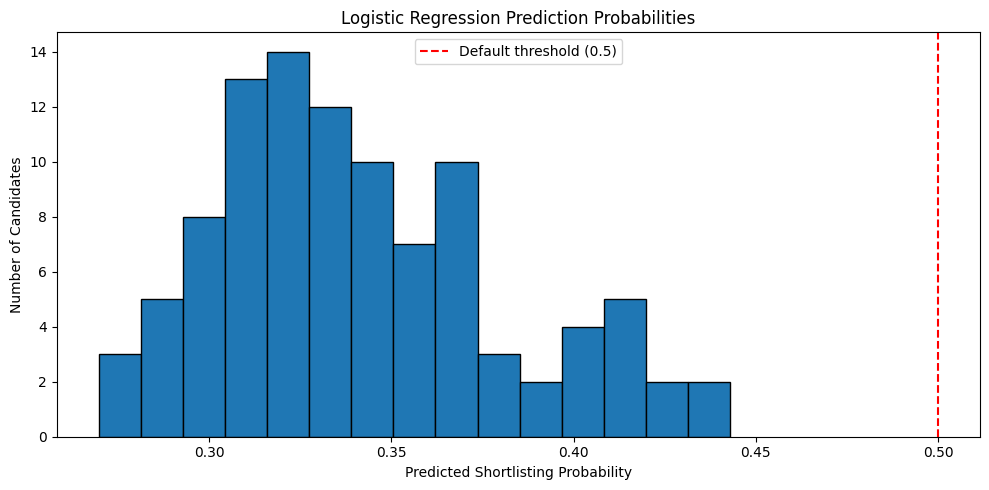

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate probabilities for the shortlisted class (1)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Display probability statistics
print("PREDICTED PROBABILITY SUMMARY:")
print(pd.Series(y_prob_lr).describe().round(4))

# Count predictions above the default threshold
print("\nCandidates with probability >= 0.5:")
print((y_prob_lr >= 0.5).sum())

# Display the highest predicted probability
print("\nHighest predicted probability:")
print(round(y_prob_lr.max(), 4))

# Visualize the probability distribution
plt.figure(figsize=(10, 5))

plt.hist(y_prob_lr, bins=15, edgecolor="black")

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    label="Default threshold (0.5)"
)

plt.xlabel("Predicted Shortlisting Probability")
plt.ylabel("Number of Candidates")
plt.title("Logistic Regression Prediction Probabilities")
plt.legend()
plt.tight_layout()
plt.show()

### 24. Testing Classification Thresholds

**Objective:** Examine how prediction thresholds affect model performance.

- `threshold` – Minimum probability required to predict class 1.
- `precision_score()` – Measures positive prediction accuracy.
- `recall_score()` – Measures detection of shortlisted candidates.
- `f1_score()` – Balances precision and recall.

**Purpose:** Understand the trade-off between missed candidates and incorrect positive predictions.

In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Define thresholds to investigate
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

# Evaluate predictions at each threshold
for threshold in thresholds:

    # Convert probabilities into class predictions
    predictions = (y_prob_lr >= threshold).astype(int)

    # Calculate performance metrics
    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    # Store the results
    results.append({
        "Threshold": threshold,
        "Predicted Shortlisted": predictions.sum(),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1-score": round(f1, 3)
    })

# Display results as a table
threshold_results = pd.DataFrame(results)

display(threshold_results)

,Threshold,Predicted Shortlisted,Precision,Recall,F1-score
0,0.20,100,0.350,1.000,0.519
1,0.25,100,0.350,1.000,0.519
2,0.30,87,0.379,0.943,0.541
3,0.35,36,0.417,0.429,0.423
4,0.40,12,0.417,0.143,0.213
5,0.45,0,0.000,0.000,0.000
6,0.50,0,0.000,0.000,0.000


### 25. Comparing Against a Dummy Classifier

**Objective:** Compare Logistic Regression with a simple baseline.

- `DummyClassifier()` – Creates a baseline classification model.
- `strategy="prior"` – Predicts using training class proportions.
- `predict()` – Generates baseline predictions.
- `accuracy_score()` – Measures prediction accuracy.

**Purpose:** Check whether Logistic Regression performs better than a model that ignores candidate features.

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

# Create a baseline classifier
dummy_model = DummyClassifier(
    strategy="prior"
)

# Train the baseline model
dummy_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_dummy = dummy_model.predict(X_test_scaled)

# Compare model performance
comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_dummy),
        accuracy_score(y_test, y_pred_lr)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_dummy, zero_division=0),
        f1_score(y_test, y_pred_lr, zero_division=0)
    ]
})

# Display comparison
display(comparison.round(3))

,Model,Accuracy,F1-score
0,Dummy Classifier,0.65,0.0
1,Logistic Regression,0.65,0.0


### 26. Training a Random Forest Classifier

**Objective:** Train and evaluate a Random Forest classification model.

- `RandomForestClassifier()` – Creates an ensemble of decision trees.
- `n_estimators=100` – Uses 100 decision trees.
- `fit()` – Trains the model.
- `predict()` – Generates shortlisting predictions.

**Purpose:** Compare Random Forest performance with our Logistic Regression baseline.

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

# Predict test outcomes
y_pred_rf = rf_model.predict(X_test_encoded)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

# Display results
print("RANDOM FOREST PERFORMANCE")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST PERFORMANCE
Accuracy: 0.61
Precision: 0.3889
Recall: 0.2
F1-score: 0.2642

Confusion Matrix:
[[54 11]
 [28  7]]


### 27. Comparing Classification Models

**Objective:** Compare Dummy Classifier, Logistic Regression, and Random Forest.

- `accuracy_score()` – Measures overall correctness.
- `precision_score()` – Evaluates positive predictions.
- `recall_score()` – Measures positive-class detection.
- `f1_score()` – Balances precision and recall.

**Purpose:** Compare model performance and identify limitations.

MODEL COMPARISON:


,Model,Accuracy,Precision,Recall,F1-score
0,Dummy Classifier,0.65,0.000,0.0,0.000
1,Logistic Regression,0.65,0.000,0.0,0.000
2,Random Forest,0.61,0.389,0.2,0.264


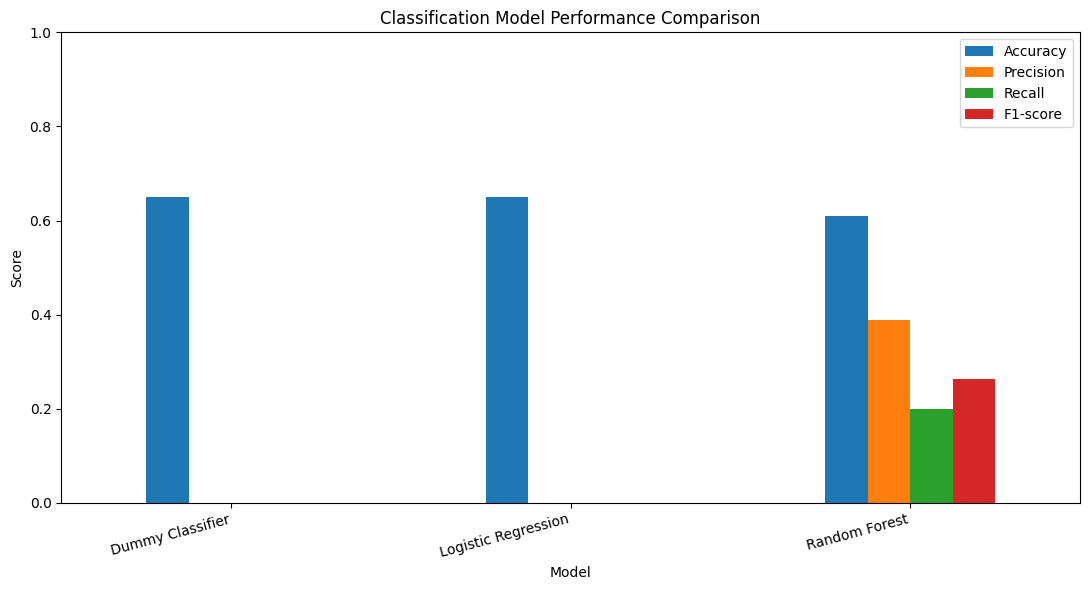

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store predictions from all three models
model_predictions = {
    "Dummy Classifier": y_pred_dummy,
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf
}

# Calculate evaluation metrics for each model
results = []

for model_name, predictions in model_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Create comparison table
model_comparison = pd.DataFrame(results)

print("MODEL COMPARISON:")
display(model_comparison.round(3))

# Create comparison chart
model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

### 28. Random Forest Feature Importance

**Objective:** Identify which features Random Forest uses most.

- `feature_importances_` – Retrieves feature importance scores.
- `sort_values()` – Ranks features by importance.
- `plt.barh()` – Creates a horizontal bar chart.

**Purpose:** Understand model behavior and investigate which features influence its predictions.

RANDOM FOREST FEATURE IMPORTANCE:


,Feature,Importance
3,keyword_density,0.2923
2,education_score,0.2318
0,years_exp,0.1880
1,skills_matched,0.1688
5,job_role_HR_Executive,0.0276
7,job_role_QA_Engineer,0.0244
4,job_role_Data_Analyst,0.0235
6,job_role_Project_Manager,0.0229
8,job_role_Software_Engineer,0.0206


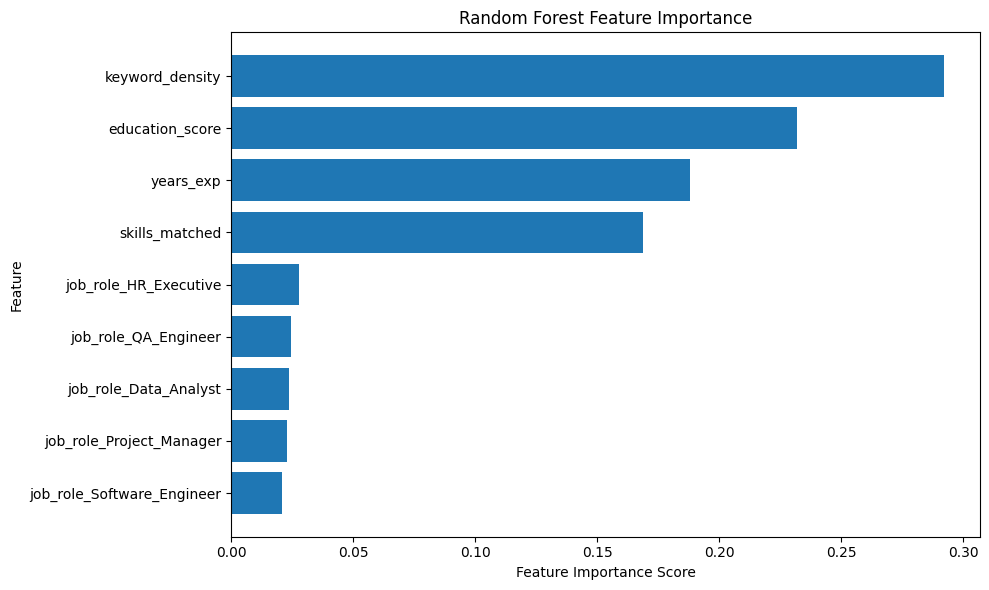

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance scores
importance_scores = rf_model.feature_importances_

# Create a feature importance table
feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": importance_scores
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the table
print("RANDOM FOREST FEATURE IMPORTANCE:")
display(feature_importance.round(4))

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

# Show the most important feature at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### 29. Permutation Feature Importance

**Objective:** Evaluate how much each feature contributes to model predictions.

- `permutation_importance()` – Measures performance changes when features are shuffled.
- `n_repeats` – Controls how many times each feature is shuffled.
- `scoring="f1"` – Evaluates changes in F1-score.

**Purpose:** Investigate whether important-looking features actually help identify shortlisted candidates.

PERMUTATION FEATURE IMPORTANCE:


,Feature,Importance,Std
2,education_score,0.2964,0.0338
3,keyword_density,0.2835,0.0255
1,skills_matched,0.2554,0.0324
0,years_exp,0.2243,0.0351
6,job_role_Project_Manager,0.0360,0.0044
5,job_role_HR_Executive,0.0330,0.0091
8,job_role_Software_Engineer,0.0322,0.0063
7,job_role_QA_Engineer,0.0268,0.0048
4,job_role_Data_Analyst,0.0230,0.0050


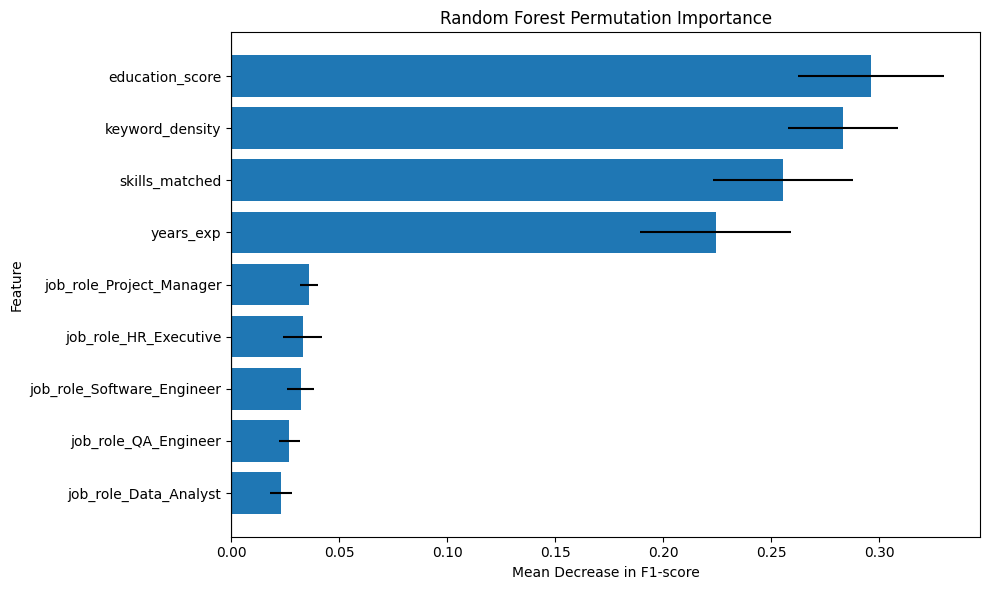

In [29]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation importance using training data
perm_result = permutation_importance(
    rf_model,
    X_train_encoded,
    y_train,
    scoring="f1",
    n_repeats=10,
    random_state=42
)

# Create an importance table
permutation_df = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort features by importance
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the results
print("PERMUTATION FEATURE IMPORTANCE:")
display(permutation_df.round(4))

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance"],
    xerr=permutation_df["Std"]
)

plt.xlabel("Mean Decrease in F1-score")
plt.ylabel("Feature")
plt.title("Random Forest Permutation Importance")

plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 30. Checking Model Overfitting

**Objective:** Compare Random Forest performance on training and testing data.

- `predict()` – Generates model predictions.
- `accuracy_score()` – Measures overall correctness.
- `f1_score()` – Measures positive-class classification performance.

**Purpose:** Detect whether the model has memorized training data instead of learning generalizable patterns.

In [30]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Generate predictions on training data
rf_train_pred = rf_model.predict(X_train_encoded)

# Generate predictions on testing data
rf_test_pred = rf_model.predict(X_test_encoded)

# Calculate performance metrics
overfitting_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, rf_train_pred),
        accuracy_score(y_test, rf_test_pred)
    ],
    "F1-score": [
        f1_score(y_train, rf_train_pred, zero_division=0),
        f1_score(y_test, rf_test_pred, zero_division=0)
    ]
})

# Display results
print("RANDOM FOREST OVERFITTING CHECK:")
display(overfitting_results.round(4))

# Calculate performance gaps
accuracy_gap = (
    overfitting_results.loc[0, "Accuracy"]
    - overfitting_results.loc[1, "Accuracy"]
)

f1_gap = (
    overfitting_results.loc[0, "F1-score"]
    - overfitting_results.loc[1, "F1-score"]
)

print("Accuracy gap:", round(accuracy_gap, 4))
print("F1-score gap:", round(f1_gap, 4))

RANDOM FOREST OVERFITTING CHECK:


,Dataset,Accuracy,F1-score
0,Training,1.00,1.0000
1,Testing,0.61,0.2642


Accuracy gap: 0.39
F1-score gap: 0.7358


### 31. Reducing Random Forest Overfitting

**Objective:** Improve model generalization by controlling tree complexity.

- `max_depth` – Limits decision tree depth.
- `min_samples_split` – Sets minimum samples needed to split a node.
- `min_samples_leaf` – Sets minimum samples in each leaf.

**Purpose:** Reduce memorization and improve performance on unseen candidates.

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Create a Random Forest with limited complexity
rf_tuned = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train the new model
rf_tuned.fit(X_train_encoded, y_train)

# Generate training predictions
y_train_pred_tuned = rf_tuned.predict(X_train_encoded)

# Generate testing predictions
y_test_pred_tuned = rf_tuned.predict(X_test_encoded)

# Compare training and testing performance
tuned_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, y_train_pred_tuned),
        accuracy_score(y_test, y_test_pred_tuned)
    ],
    "F1-score": [
        f1_score(y_train, y_train_pred_tuned, zero_division=0),
        f1_score(y_test, y_test_pred_tuned, zero_division=0)
    ]
})

print("REGULARIZED RANDOM FOREST PERFORMANCE:")
display(tuned_results.round(4))

# Compare performance gaps
print(
    "Accuracy gap:",
    round(
        tuned_results.loc[0, "Accuracy"]
        - tuned_results.loc[1, "Accuracy"],
        4
    )
)

print(
    "F1-score gap:",
    round(
        tuned_results.loc[0, "F1-score"]
        - tuned_results.loc[1, "F1-score"],
        4
    )
)

REGULARIZED RANDOM FOREST PERFORMANCE:


,Dataset,Accuracy,F1-score
0,Training,0.6675,0.0699
1,Testing,0.6400,0.0000


Accuracy gap: 0.0275
F1-score gap: 0.0699


### 32. Evaluating Models Using Cross-Validation

**Objective:** Measure model performance across multiple validation folds.

- `StratifiedKFold()` – Creates balanced validation folds.
- `cross_validate()` – Evaluates a model across multiple folds.
- `scoring` – Measures accuracy, precision, recall, and F1-score.

**Purpose:** Assess model stability without using the test set for model selection.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Create five stratified validation folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the two Random Forest models
models = {
    "Original Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Regularized Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    )
}

# Store cross-validation results
cv_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train_encoded,
        y_train,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1"
        }
    )

    cv_results.append({
        "Model": model_name,
        "Mean Accuracy": scores["test_Accuracy"].mean(),
        "Mean Precision": scores["test_Precision"].mean(),
        "Mean Recall": scores["test_Recall"].mean(),
        "Mean F1": scores["test_F1"].mean(),
        "F1 Std": scores["test_F1"].std()
    })

# Display comparison
cv_comparison = pd.DataFrame(cv_results)

print("5-FOLD CROSS-VALIDATION RESULTS:")
display(cv_comparison.round(4))

5-FOLD CROSS-VALIDATION RESULTS:


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,F1 Std
0,Original Random Forest,0.5625,0.1365,0.0582,0.0811,0.0595
1,Regularized Random Forest,0.6300,0.0333,0.0074,0.0121,0.0242


### 33. Random Forest Hyperparameter Tuning

**Objective:** Improve Random Forest using training-only cross-validation.

- `RandomizedSearchCV()` – Tests different model configurations.
- `StratifiedKFold()` – Maintains class proportions across folds.
- `class_weight` – Adjusts how strongly the model penalizes class errors.
- `scoring="f1"` – Prioritizes positive-class F1-score.

**Purpose:** Find a more effective configuration without tuning against the test set.

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import pandas as pd

# Create the base model
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# Define hyperparameter options
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

# Create stratified cross-validation folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for better hyperparameters
rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

# Train and evaluate configurations using training data
rf_search.fit(X_train_encoded, y_train)

# Display the best configuration
print("BEST HYPERPARAMETERS:")
print(rf_search.best_params_)

print("\nBEST CROSS-VALIDATION F1-SCORE:")
print(round(rf_search.best_score_, 4))

# Store the selected model
rf_best = rf_search.best_estimator_

# Display the top five configurations
search_results = pd.DataFrame(rf_search.cv_results_)

top_results = search_results[
    ["rank_test_score", "mean_test_score", "std_test_score", "params"]
].sort_values("rank_test_score").head(5)

print("\nTOP 5 CONFIGURATIONS:")
display(top_results)

BEST HYPERPARAMETERS:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_depth': 3, 'class_weight': 'balanced_subsample'}

BEST CROSS-VALIDATION F1-SCORE:
0.2857

TOP 5 CONFIGURATIONS:


,rank_test_score,mean_test_score,std_test_score,params
10,1,0.285712,0.064091,"{'n_estimators': 200, 'min_samples_split': 5, ..."
18,2,0.277903,0.046008,"{'n_estimators': 100, 'min_samples_split': 10,..."
2,3,0.234650,0.059420,"{'n_estimators': 100, 'min_samples_split': 2, ..."
7,4,0.226363,0.051177,"{'n_estimators': 200, 'min_samples_split': 2, ..."
15,5,0.221854,0.056639,"{'n_estimators': 100, 'min_samples_split': 5, ..."


### 34. Saving the Trained ML Model

**Objective:** Save the selected Random Forest model and preprocessing components.

- `joblib.dump()` – Saves trained Python objects.
- `os.makedirs()` – Creates a folder for model files.

**Purpose:** Prepare the ML components for integration with the Flask backend.

In [34]:
import joblib
import os

# Create a folder to store ML files
model_dir = "/kaggle/working/models"
os.makedirs(model_dir, exist_ok=True)

# Save the selected Random Forest model
joblib.dump(
    rf_best,
    f"{model_dir}/random_forest_model.pkl"
)

# Save the job-role encoder
joblib.dump(
    encoder,
    f"{model_dir}/job_role_encoder.pkl"
)

# Save the feature scaler
joblib.dump(
    scaler,
    f"{model_dir}/feature_scaler.pkl"
)

# Save the feature order required by the Random Forest
joblib.dump(
    X_train_encoded.columns.tolist(),
    f"{model_dir}/feature_columns.pkl"
)

# Verify saved files
print("SAVED ML FILES:")

for filename in sorted(os.listdir(model_dir)):
    print("✓", filename)

SAVED ML FILES:
✓ feature_columns.pkl
✓ feature_scaler.pkl
✓ job_role_encoder.pkl
✓ random_forest_model.pkl


### 35. Resume Text Extraction

**Objective:** Extract readable text from PDF and DOCX resumes.

- `pdfminer.six` – Extracts text from PDF files.
- `python-docx` – Extracts text from Word documents.
- `extract_resume_text()` – Supports both file formats.

**Purpose:** Prepare resume text for NLP-based job matching.

In [35]:
# Install document processing libraries
!pip -q install pdfminer.six python-docx

from pdfminer.high_level import extract_text
from docx import Document
import os

def extract_resume_text(file_path):

    # Check whether the file exists
    if not os.path.isfile(file_path):
        raise FileNotFoundError("Resume file not found.")

    # Identify the file format
    extension = os.path.splitext(file_path)[1].lower()

    if extension == ".pdf":
        text = extract_text(file_path)

    elif extension == ".docx":
        document = Document(file_path)

        paragraphs = [
            paragraph.text
            for paragraph in document.paragraphs
        ]

        # Include text inside Word tables
        for table in document.tables:
            for row in table.rows:
                for cell in row.cells:
                    paragraphs.append(cell.text)

        text = "\n".join(paragraphs)

    else:
        raise ValueError("Only PDF and DOCX files are supported.")

    # Remove unnecessary whitespace
    cleaned_text = " ".join(text.split())

    return cleaned_text


print("Resume text extraction function created successfully!")
print("Supported formats: PDF, DOCX")

Resume text extraction function created successfully!
Supported formats: PDF, DOCX


### 36. Resume and Job Description Matching

**Objective:** Calculate resume-job similarity using NLP.

- `TfidfVectorizer()` – Converts text into numerical features.
- `cosine_similarity()` – Measures similarity between documents.
- `match_resume()` – Returns a resume matching score.

**Purpose:** Provide an explainable, text-based matching score for recruiter review.

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def match_resume(resume_text, job_description):

    # Validate inputs
    if not resume_text.strip() or not job_description.strip():
        raise ValueError("Resume and job description cannot be empty.")

    # Convert both texts into TF-IDF vectors
    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    tfidf_matrix = vectorizer.fit_transform([
        resume_text,
        job_description
    ])

    # Calculate cosine similarity
    similarity = cosine_similarity(
        tfidf_matrix[0:1],
        tfidf_matrix[1:2]
    )[0][0]

    # Convert similarity to a percentage
    match_score = round(float(similarity) * 100, 2)

    return match_score


# Sample resume
sample_resume = """
Python developer with experience in machine learning,
data analysis, pandas, numpy, SQL, Flask,
scikit-learn and natural language processing.
Built machine learning projects and REST APIs.
"""

# Sample job description
sample_job = """
Looking for a Python developer with experience in
machine learning, SQL, pandas, scikit-learn,
Flask and REST API development.
"""

# Calculate matching score
score = match_resume(sample_resume, sample_job)

print("RESUME MATCHING RESULT")
print("----------------------")
print(f"Resume Match Score: {score}%")

RESUME MATCHING RESULT
----------------------
Resume Match Score: 36.35%


### 37. Final NLP Matching Engine

**Objective:** Create and save a reusable resume-screening module.

- Extract text from PDF and DOCX resumes.
- Calculate resume-to-job similarity using TF-IDF.
- Save the functions for backend integration.

**Purpose:** Complete the NLP component of the AI-Based Resume Screening System.

In [37]:
import os
import importlib.util

# Create project folder
project_dir = "/kaggle/working/resume_screening"
os.makedirs(project_dir, exist_ok=True)

# Create reusable Python module
module_code = '''
import os
from pdfminer.high_level import extract_text
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def extract_resume_text(file_path):
    if not os.path.isfile(file_path):
        raise FileNotFoundError("Resume file not found.")

    extension = os.path.splitext(file_path)[1].lower()

    if extension == ".pdf":
        text = extract_text(file_path)

    elif extension == ".docx":
        document = Document(file_path)

        parts = [p.text for p in document.paragraphs]

        for table in document.tables:
            for row in table.rows:
                for cell in row.cells:
                    parts.append(cell.text)

        text = "\\n".join(parts)

    else:
        raise ValueError("Only PDF and DOCX files are supported.")

    return " ".join(text.split())


def match_resume(resume_text, job_description):
    if not resume_text.strip() or not job_description.strip():
        raise ValueError("Resume and job description cannot be empty.")

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    matrix = vectorizer.fit_transform([
        resume_text,
        job_description
    ])

    similarity = cosine_similarity(
        matrix[0:1],
        matrix[1:2]
    )[0][0]

    return round(float(similarity) * 100, 2)


def screen_resume(file_path, job_description):
    resume_text = extract_resume_text(file_path)

    if not resume_text:
        raise ValueError("No readable text found in resume.")

    return {
        "filename": os.path.basename(file_path),
        "match_score": match_resume(
            resume_text,
            job_description
        ),
        "status": "Human review required"
    }
'''

# Save module as a Python file
module_path = os.path.join(project_dir, "nlp_engine.py")

with open(module_path, "w", encoding="utf-8") as file:
    file.write(module_code)

# Load saved module to verify it works
spec = importlib.util.spec_from_file_location(
    "nlp_engine",
    module_path
)

nlp_engine = importlib.util.module_from_spec(spec)
spec.loader.exec_module(nlp_engine)

# Test saved module with Step 36 sample text
test_score = nlp_engine.match_resume(
    sample_resume,
    sample_job
)

print("NLP ENGINE VERIFICATION")
print("-----------------------")
print("Module saved:", os.path.isfile(module_path))
print("Module path:", module_path)
print("Test match score:", test_score, "%")
print("Functions available:")
print("- extract_resume_text")
print("- match_resume")
print("- screen_resume")

NLP ENGINE VERIFICATION
-----------------------
Module saved: True
Module path: /kaggle/working/resume_screening/nlp_engine.py
Test match score: 36.35 %
Functions available:
- extract_resume_text
- match_resume
- screen_resume


In [38]:
import os
import zipfile

output_zip = "/kaggle/working/ai_resume_project_files.zip"

files_to_save = [
    "/kaggle/working/models/random_forest_model.pkl",
    "/kaggle/working/models/job_role_encoder.pkl",
    "/kaggle/working/models/feature_scaler.pkl",
    "/kaggle/working/models/feature_columns.pkl",
    "/kaggle/working/resume_screening/nlp_engine.py"
]

with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in files_to_save:
        if os.path.isfile(file_path):
            zipf.write(
                file_path,
                arcname=os.path.relpath(
                    file_path,
                    "/kaggle/working"
                )
            )
            print("Added:", os.path.basename(file_path))
        else:
            print("Missing:", file_path)

print("\nZIP created:", output_zip)

Added: random_forest_model.pkl
Added: job_role_encoder.pkl
Added: feature_scaler.pkl
Added: feature_columns.pkl
Added: nlp_engine.py

ZIP created: /kaggle/working/ai_resume_project_files.zip


In [ ]:
import os

print("ZIP exists:", os.path.exists("/kaggle/working/ai_resume_project_files.zip"))
print("NLP file exists:", os.path.exists("/kaggle/working/resume_screening/nlp_engine.py"))
print("Working folder:", os.listdir("/kaggle/working"))